In [178]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
import pandas as pd

## Initializing the Max-Cut example
#### (same 3-node problem instance considered in `MaxCut-QUBO-BruteForce.ipynb`)

In [179]:
# Example graph with 3 nodes and weighted edges
edge_dict = {
    ('A', 'B'): 8,
    ('A', 'C'): -2,
    ('B', 'C'): -3
}

G = nx.Graph()

for (u, v), weight in edge_dict.items():
    G.add_edge(u, v, weight=weight)

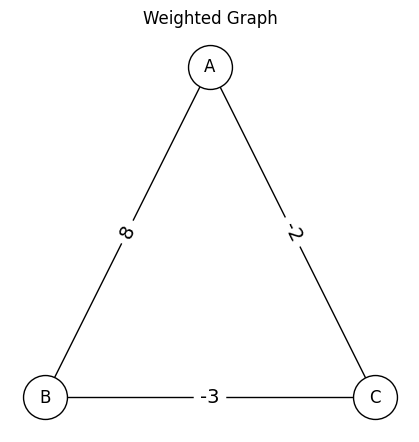

In [180]:
plt.figure(figsize=(4,4))
# Custom layout: node A at top, nodes B and C at bottom horizontally
pos = {'A': (0.5, 1.0),'B': (0, 0),'C': (1, 0)}
# Draw the graph
nx.draw(G, pos, with_labels=True, node_color="white", node_size=1000, edgecolors="black", linewidths=1)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=14)
plt.title("Weighted Graph")
plt.show()

Given a connected, undirected, weighted graph, the goal is to split the set of vertices into two mutually exclusive subsets by cutting the edges such that the sum of the edges that are cut is maximum.

## Computing the QUBO matrix Q for the MaxCut problem

In [181]:
def get_maxcut_qubo_matrix(W):
    """Computes the QUBO matrix for the Maximum Cut problem given a weight matrix W."""
    n = W.shape[0]  # Number of nodes
    Q = np.zeros((n, n))  # Initialize QUBO matrix
    for i in range(n):
        Q[i, i] = np.sum(-W[i])  # Diagonal terms (degree of node)
        for j in range(n):
            if i != j:
                Q[i, j] = W[i, j]  # Off-diagonal terms (negative adjacency)
    return Q

Q = get_maxcut_qubo_matrix(nx.adjacency_matrix(G).toarray())
Q

array([[-6.,  8., -2.],
       [ 8., -5., -3.],
       [-2., -3.,  5.]])

## Solving using D-Wave Quantum Annealer

In [182]:
# ! pip install dwave-ocean-sdk==9.5.0

In [183]:
import dimod
from dwave.system import DWaveSampler, EmbeddingComposite

In [189]:
def generate_graph(num_nodes, weight_range=(-1, 1), random_seed=123):
    """
    Generate a random weighted graph.
    :param num_nodes: Number of nodes in the graph.
    :param weight_range: Range of weights for the edges (tuple, inclusive).
    :param random_seed: Seed for the random number generator.
    :return: Dictionary {(i, j): weight} representing the edges and their weights.
    """
    np.random.seed(random_seed)
    edge_dict = {}
    for i in range(1, num_nodes + 1):
        for j in range(i + 1, num_nodes + 1):
            weight = round(np.random.uniform(weight_range[0], weight_range[1]), 2)
            edge_dict[(i, j)] = weight
    G = nx.Graph()
    
    for (u, v), weight in edge_dict.items():
        G.add_edge(u, v, weight=weight)
    return G, edge_dict

In [191]:
def get_maxcut_qubo_matrix(W):
    """Computes the QUBO matrix for the Maximum Cut problem given a weight matrix W."""
    n = W.shape[0]  # Number of nodes
    Q = np.zeros((n, n))  # Initialize QUBO matrix
    for i in range(n):
        Q[i, i] = np.sum(-W[i])  # Diagonal terms (degree of node)
        for j in range(n):
            if i != j:
                Q[i, j] = W[i, j]  # Off-diagonal terms (negative adjacency)
    return Q

Q = get_maxcut_qubo_matrix(nx.adjacency_matrix(G).toarray())
Q

array([[ 0.49,  0.39, -0.43, -0.55,  0.1 ],
       [ 0.39, -1.64,  0.44, -0.15,  0.96],
       [-0.43,  0.44, -0.34,  0.37, -0.04],
       [-0.55, -0.15,  0.37,  0.55, -0.22],
       [ 0.1 ,  0.96, -0.04, -0.22, -0.8 ]])

In [ ]:
n = Q.shape[0]
# 1. Instantly convert the numpy matrix to an optimized BQM object
# bqm = dimod.BQM.from_numpy_matrix(Q)
bqm = dimod.BQM(Q, "BINARY")

qpu = DWaveSampler(token = "")
sampler = EmbeddingComposite(qpu)
sampleset = sampler.sample(bqm, num_reads=100, embedding_parameters={"random_seed": 999}, label="Max-Cut as QUBO")

# 4. Extract the optimal solution
# D-Wave returns an ordered list of samples; the first one has the lowest energy
best_sample = sampleset.first.sample
best_energy = sampleset.first.energy
# 5. Convert dictionary response back into an ordered 0/1 array matching Q's indices
optimal_x = np.array([best_sample[i] for i in range(n)], dtype=int)

print("Optimal solution (binary vector):", optimal_x)
print("Optimal cost:", best_energy)

## Visualizing the MaxCut Solution

The optimal binary vector partitions the graph into two sets:
- Nodes with $ x_i = 0 $
- Nodes with $ x_i = 1 $

We can highlight the cut edges in red color


In [ ]:
# Get sorted node labels to match the order of optimal_x
node_labels = sorted(list(G.nodes()))

# Identify nodes in each partition using actual node labels
partition_0 = [node_labels[i] for i, val in enumerate(optimal_x) if val == 0]
partition_1 = [node_labels[i] for i, val in enumerate(optimal_x) if val == 1]

# Assign colors to nodes based on partition
node_colors = []
for node in node_labels:
    if node in partition_0:
        node_colors.append("green")  # Nodes in partition 0
    elif node in partition_1:
        node_colors.append("blue")   # Nodes in partition 1
print(node_colors)
# Highlight the edges in the cut
cut_edges = [(u, v) for u, v in G.edges if (u in partition_0 and v in partition_1) or (u in partition_1 and v in partition_0)]
print(cut_edges)
# Plot the graph with node colors and cut edges
plt.figure(figsize=(4, 4))
nx.draw(G, pos, with_labels=True, node_color=node_colors, node_size=1000)
nx.draw_networkx_edges(G, pos, edgelist=cut_edges, edge_color="red", width=2)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=12)
plt.title("Partitioned Graph with Cut Edges")
plt.show()